# 可转债双低榜 + 估值通道拨测（wmshare notebook）

只用 [wmshare](https://github.com/open-winmale/wmshare) 一个数据源。数据面 = 两次调用：

- **`cli.cbond.board()`**——转债全市场面板：快照行 + 每债最新条款事件 + 盘中债价
  + 强赎触发计数 `callHits`（服务端按 30 交易日窗统计）+ 下修地板价 `resetFloor`
- **`cli.cbond.event_list()`**——条款事件流（下修提案/实施、强赎/不强赎、回售等 9 类）
- featured 债另加 `cli.cbond.kline_window`（转债日 K，列式 OHLCV）

**口径（先读再跑）**
- 双低 = 转债价格 + 转股溢价率×100；`premiumRatio` 字段为**小数**（0.0752 = 7.52%）
- 「在市」= 快照行 `bondPrice` 与 `premiumRatio` 均非空（全表含已退出合约的档案行）
- 正股 ST 取自证券简称含「ST」（*ST/ST 同判）——以交易所风险警示简称为准
- 税后 YTM 为**下限口径**：票息取 `couponIr` 恒定、利息税 20%、剩余不足半年不年化、
  赎回价未知按面值 100 兑付（真实赎回价恒 ≥ 面值，故真值 ≥ 下限）
- 债性分类：偏债 = YTM 下限 > 0；偏股 = 价格 ≥ 130 且溢价率 ≤ 15%；其余平衡（行业惯例，非官方阈值）
- 通道 = 上市以来均值 ± Nσ（总体标准差）；**位置描述非买卖信号**

实测日期 **2026-11-07**（真实数据，页脚复现口径见文末）。
本例全部输出为数据整理与研究参考，不构成任何投资建议。

In [1]:
import math
import os
from collections import Counter
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.sans-serif"] = ["Hiragino Sans GB", "PingFang SC",
                                   "Arial Unicode MS", "SimHei", "sans-serif"]

from wmshare import Client


def load_credentials() -> None:
    """凭证从 ~/.wmshare/credentials.env 读（也可直接 export WMSHARE_CLIENT_ID/SECRET）。"""
    for p in (Path.home() / ".wmshare/credentials.env",
              Path.home() / ".winmale/credentials.env"):
        if not p.exists():
            continue
        for line in p.read_text(encoding="utf-8").splitlines():
            line = line.strip()
            if line and not line.startswith("#") and "=" in line:
                k, v = line.split("=", 1)
                os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))


load_credentials()
cli = Client.from_env()
print("wmshare 客户端就绪")

wmshare 客户端就绪


In [2]:
# ---- 口径工具：双低 / YTM 下限 / 债性 / ST ----

def days_between(d1: str, d2: str) -> float:
    """d2 − d1 的天数（解析失败返回 0）。"""
    try:
        a = datetime.strptime(d1[:10], "%Y-%m-%d")
        b = datetime.strptime(d2[:10], "%Y-%m-%d")
        return (b - a).days
    except Exception:
        return 0.0


def ytm_floor(price: float, coupon_ir, years: float, tax: float = 0.20):
    """税后到期收益率下限（单利年化）。
    赎回价未知按面值 100 兑付 → 真值 ≥ 此下限；剩余 < 0.5 年不年化。"""
    if coupon_ir is None or not price or years < 0.5:
        return None
    coupons = years * coupon_ir * 100 * (1 - tax)
    return (100.0 + coupons - price) / price / years


def nature_class(price: float, prem_pct: float, ytm):
    """偏债 / 平衡 / 偏股（行业惯例规则，非官方）。"""
    if ytm is not None and ytm > 0:
        return "偏债"
    if price >= 130 and prem_pct <= 15:
        return "偏股"
    return "平衡"


def is_st(stock_name) -> bool:
    """正股 ST 判定：证券简称含 ST（*ST/ST 同判，以交易所风险警示简称为准）。"""
    return "ST" in str(stock_name or "")


# ---- 一次调用取全市场面板 ----
rows = cli.cbond.board()
rows = rows if isinstance(rows, list) else rows.get("rows", [])
asof = max((str(r.get("asOf"))[:10] for r in rows if isinstance(r, dict) and r.get("asOf")),
           default="")

traded = []
for r in rows:
    if not isinstance(r, dict):
        continue
    px, prem = r.get("bondPrice"), r.get("premiumRatio")
    if isinstance(px, (int, float)) and px and isinstance(prem, (int, float)):
        r = dict(r)  # 不改原始行
        r["_price"] = float(px)
        r["_prem_pct"] = float(prem) * 100          # 小数 → 百分数展示
        r["_dl"] = r["_price"] + r["_prem_pct"]     # 双低 = 价格 + 溢价率×100
        yrs = days_between(asof, str(r.get("expireDate") or "")) / 365.0
        r["_ytm"] = ytm_floor(r["_price"], r.get("couponIr"), yrs)
        r["_nature"] = nature_class(r["_price"], r["_prem_pct"], r["_ytm"])
        r["_st"] = is_st(r.get("stockName"))
        traded.append(r)

traded.sort(key=lambda r: r["_dl"])
print(f"board 全表 {len(rows)} 行 · 在市 {len(traded)} 只 · 数据截至 {asof}")
print("口径：双低 = 价格(元) + 转股溢价率(小数)×100；在市 = bondPrice 与 premiumRatio 均非空")

board 全表 1066 行 · 在市 310 只 · 数据截至 2026-11-06
口径：双低 = 价格(元) + 转股溢价率(小数)×100；在市 = bondPrice 与 premiumRatio 均非空


## 一、双低榜前 20

按双低升序。**先看警示列再看排名**：双低最低的债往往伴随 ST 正股——
低价的来源可能是信用风险而不是便宜（2023–2024 年搜特、蓝盾、鸿达、岭南
四只违约债，当时都曾交易在百元附近）。

In [3]:
HEADERS = ["转债", "代码", "价格(元)", "溢价率", "双低", "税后YTM(下限)", "债性", "正股", "警示"]
widths = (10, 8, 9, 8, 8, 13, 5, 12, 8)
print("  ".join(h.ljust(w) for h, w in zip(HEADERS, widths)))
print("-" * 96)
for r in traded[:20]:
    ytm = f"{r['_ytm'] * 100:.2f}%" if r["_ytm"] is not None else "—"
    cols = [r.get("bondName") or "", r.get("bondCode") or "", f"{r['_price']:.2f}",
            f"{r['_prem_pct']:.2f}%", f"{r['_dl']:.2f}", ytm, r["_nature"],
            r.get("stockName") or "", "ST" if r["_st"] else "—"]
    print("  ".join(c.ljust(w) for c, w in zip(cols, widths)))

mean_dl = sum(r["_dl"] for r in traded) / len(traded)
srt = sorted(r["_dl"] for r in traded)
n = len(srt)
median_dl = srt[n // 2] if n % 2 else (srt[n // 2 - 1] + srt[n // 2]) / 2
print(f"\n全市场双低均值 {mean_dl:.2f} · 中位数 {median_dl:.2f}"
      f"（中位数低于均值 = 少数高双低个债拉高了均值，两个数对照看）")

转债          代码        价格(元)      溢价率       双低        税后YTM(下限)      债性     正股            警示      
------------------------------------------------------------------------------------------------
宏图转债        118027    86.55      7.02%     93.57     8.92%          偏债     *ST航图         ST      
美锦转债        127061    97.50      4.42%     101.92    3.81%          偏债     美锦能源          —       
东时转债        113575    81.44      32.34%    113.78    —              平衡     ST东时          ST      
三房转债        110092    70.69      50.34%    121.03    20.81%         偏债     *ST三房         ST      
新乳转债        128142    110.46     11.99%    122.45    —              平衡     新乳业           —       
财通转债        113043    106.72     15.86%    122.58    —              平衡     财通证券          —       
温氏转债        123107    114.80     9.82%     124.62    —              平衡     温氏股份          —       
上银转债        113042    113.53     11.59%    125.12    —              平衡     上海银行          —       
重银转债        113056   

In [4]:
# ---- 温度计：价格分布 / YTM 为正 / 强赎与下修观测（board 行自带）----
bins = {"<100（破面）": 0, "100–110": 0, "110–130": 0, "≥130（强赎区）": 0}
ytm_pos = 0
for r in traded:
    p = r["_price"]
    if p < 100:
        bins["<100（破面）"] += 1
    elif p < 110:
        bins["100–110"] += 1
    elif p < 130:
        bins["110–130"] += 1
    else:
        bins["≥130（强赎区）"] += 1
    if r["_ytm"] is not None and r["_ytm"] > 0:
        ytm_pos += 1

for k, v in bins.items():
    print(f"{k:<12} {v:>4} 只")
print(f"{'YTM下限>0':<12} {ytm_pos:>4} 只（信用筛子过滤后的候选池，不是买入名单）")
print(f"{'在市合计':<12} {len(traded):>4} 只")

# 强赎观测：board 行 callHits = 服务端统计的近窗（callWindow）满足天数
hits_rows = [r for r in traded if isinstance(r.get("callHits"), (int, float))]
active = sorted([r for r in hits_rows if r["callHits"] > 0],
                key=lambda r: -r["callHits"])
print(f"\n强赎观测（服务端 30 交易日窗计数，勿以单日价判定已满足，15/30 规则另行判读）：")
print(f"  有触发价观测 {len(hits_rows)} 只，近窗已满足天数 >0 的 {len(active)} 只")
for r in active[:5]:
    print(f"    {r.get('bondName')}（{r['bondCode']}）{int(r['callHits'])} 天"
          f"（触发价 {r.get('redeemTrig')}）")

# 下修观测：board 行 resetFloor = 下修地板价测算（提案/实施中才有值）
floors = [r for r in traded if r.get("resetFloor") is not None]
print(f"\n下修观测（resetFloor = 条款测算的下修地板价，测算中 {len(floors)} 只）：")
for r in floors[:5]:
    print(f"    {r.get('bondName')}（{r['bondCode']}）地板价 {r['resetFloor']:.2f}"
          f"（现价 {r['_price']:.2f}）")

<100（破面）        5 只
100–110         8 只
110–130       154 只
≥130（强赎区）     143 只
YTM下限>0         4 只（信用筛子过滤后的候选池，不是买入名单）
在市合计          310 只

强赎观测（服务端 30 交易日窗计数，勿以单日价判定已满足，15/30 规则另行判读）：
  有触发价观测 30 只，近窗已满足天数 >0 的 29 只
    冠中转债（123207）30 天（触发价 13.57）
    万凯转债（123247）30 天（触发价 14.5）
    超达转债（123187）30 天（触发价 28.3）
    金25转债（113699）30 天（触发价 81.64）
    声迅转债（127080）30 天（触发价 37.62）

下修观测（resetFloor = 条款测算的下修地板价，测算中 12 只）：
    闻泰转债（110081）地板价 11.93（现价 88.24）
    绿茵转债（127034）地板价 7.95（现价 117.62）
    麒麟转债（127050）地板价 13.01（现价 121.92）
    三角转债（123114）地板价 18.61（现价 123.86）
    芳源转债（118020）地板价 4.96（现价 111.74）


## 二、全市场双低价差图

横轴价格、纵轴溢价率，越靠左下双低越小。三色 = 债性分类。

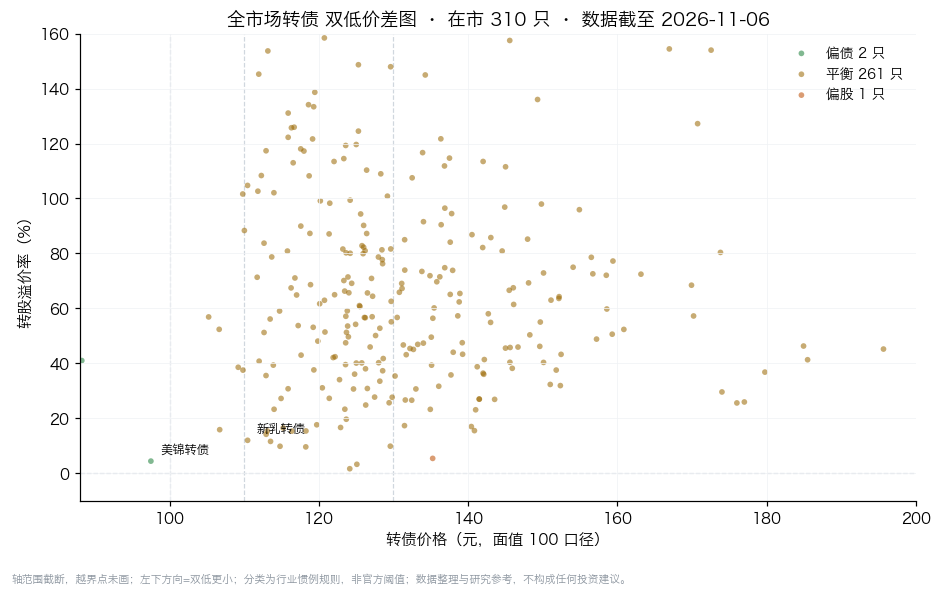

In [5]:
colors = {"偏债": "#1a7f37", "平衡": "#9a6700", "偏股": "#bc4c00"}
X_MIN, X_MAX, Y_MIN, Y_MAX = 88, 200, -10, 160

fig, ax = plt.subplots(figsize=(8.6, 5.4), dpi=110)
for nature, color in colors.items():
    xs = [r["_price"] for r in traded
          if r["_nature"] == nature and X_MIN <= r["_price"] <= X_MAX
          and Y_MIN <= r["_prem_pct"] <= Y_MAX]
    ys = [r["_prem_pct"] for r in traded
          if r["_nature"] == nature and X_MIN <= r["_price"] <= X_MAX
          and Y_MIN <= r["_prem_pct"] <= Y_MAX]
    ax.scatter(xs, ys, s=14, c=color, alpha=0.55, label=f"{nature} {len(xs)} 只", edgecolors="none")

for r in traded[:5]:
    if X_MIN <= r["_price"] <= X_MAX and Y_MIN <= r["_prem_pct"] <= Y_MAX:
        ax.annotate(r.get("bondName") or "", (r["_price"], r["_prem_pct"]),
                    textcoords="offset points", xytext=(6, 5), fontsize=8)

for xv in (100, 110, 130):
    ax.axvline(xv, color="#d0d7de", lw=0.8, ls="--", zorder=0)
ax.axhline(0, color="#d0d7de", lw=0.8, ls="--", zorder=0)

ax.set_title(f"全市场转债 双低价差图 · 在市 {len(traded)} 只 · 数据截至 {asof}", fontsize=12)
ax.set_xlabel("转债价格（元，面值 100 口径）")
ax.set_ylabel("转股溢价率（%）")
ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(Y_MIN, Y_MAX)
ax.grid(True, color="#f0f2f5", lw=0.5)
ax.legend(loc="upper right", frameon=False, fontsize=9)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.text(0.01, 0.01, "轴范围截断，越界点未画；左下方向=双低更小；分类为行业惯例规则，非官方阈值；"
                     "数据整理与研究参考，不构成任何投资建议。", fontsize=7, color="#8b949e")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## 三、估值通道拨测（featured 债）

`cli.cbond.kline_window` 返回转债日 K（列式 OHLCV，`samplingName` 为日期、**降序**，
客户端转升序）。通道 = 上市以来均值 ± Nσ（总体标准差），标注现价 z 值与价格分位。
日 K 陈旧（最后一根 ≠ 快照日，常见于临近赎回/停牌债）的债自动跳过——这本身就是
「在市」口径的一层审计。

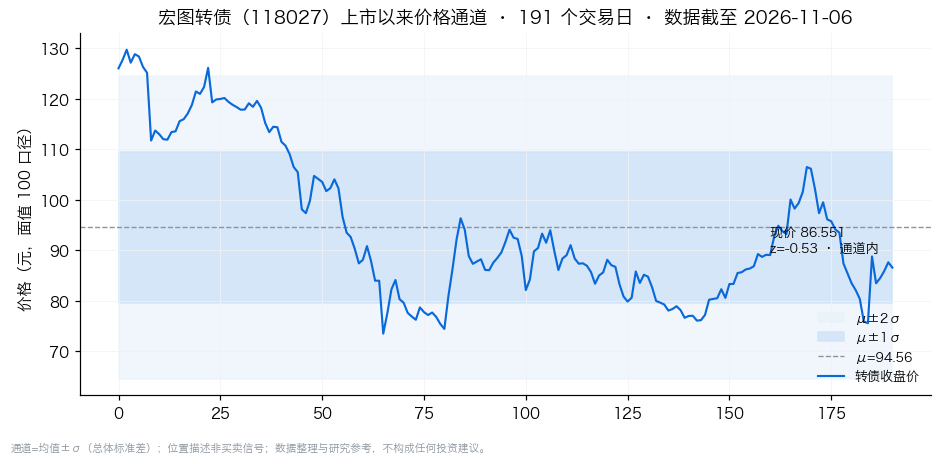

宏图转债: z=-0.53 · 价格分位 37.4% · 通道内 （按上市以来 191 个交易日计算）



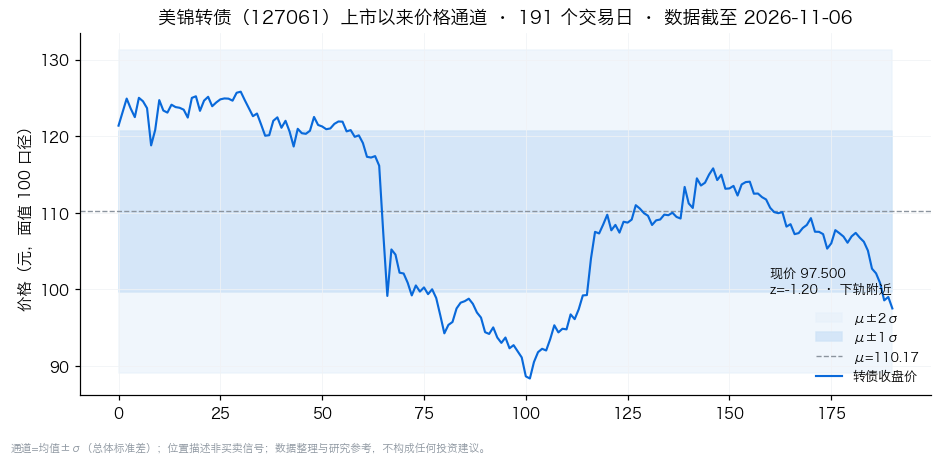

美锦转债: z=-1.20 · 价格分位 15.8% · 下轨附近 （按上市以来 191 个交易日计算）

[kline] 113575 东时转债 日K陈旧（最后一根 2026-04-08 ≠ 快照日 2026-11-06），跳过


In [6]:
def channel(closes: list) -> dict:
    """均值 ± 1σ/2σ 通道 + z 值 + 分位（自包含实现）。"""
    n = len(closes)
    mu = sum(closes) / n
    sd = math.sqrt(sum((c - mu) ** 2 for c in closes) / n) or 1e-9
    last = closes[-1]
    z = (last - mu) / sd
    pct = sum(1 for c in closes if c < last) / max(1, n - 1)
    zone = "下轨附近" if z <= -1 else ("上轨附近" if z >= 1 else "通道内")
    return {"mu": mu, "lower1": mu - sd, "upper1": mu + sd,
            "lower2": mu - 2 * sd, "upper2": mu + 2 * sd, "z": z, "pct": pct, "zone": zone}


FEATURED_N = 3   # 拨测只取双低榜前 3 只，控制请求数
for r in traded[:FEATURED_N]:
    code, name = r["bondCode"], r.get("bondName") or ""
    try:
        kw = cli.cbond.kline_window(code, 300)
    except Exception as e:
        print(f"[kline] {code} {name} 不可用：{e}")
        continue
    closes = [float(c) for c in (kw.get("close") or [])][::-1]
    dates = list(kw.get("samplingName") or [])[::-1]
    if not closes:
        print(f"[kline] {code} {name} 无日 K")
        continue
    if dates and dates[-1] != asof:
        print(f"[kline] {code} {name} 日K陈旧（最后一根 {dates[-1]} ≠ 快照日 {asof}），跳过")
        continue

    ch = channel(closes)
    x = list(range(len(closes)))
    fig, ax = plt.subplots(figsize=(8.6, 4.2), dpi=110)
    ax.fill_between(x, ch["lower2"], ch["upper2"], color="#e7f0fa", alpha=0.6, label="μ±2σ")
    ax.fill_between(x, ch["lower1"], ch["upper1"], color="#cfe3f7", alpha=0.8, label="μ±1σ")
    ax.axhline(ch["mu"], color="#8b949e", lw=0.9, ls="--", label=f"μ={ch['mu']:.2f}")
    ax.plot(x, closes, color="#0969da", lw=1.4, label="转债收盘价")
    ax.annotate(f"现价 {closes[-1]:.3f}\nz={ch['z']:+.2f} · {ch['zone']}",
                (len(closes) - 1, closes[-1]), textcoords="offset points",
                xytext=(-80, 10), fontsize=8.5)
    ax.set_title(f"{name}（{code}）上市以来价格通道 · {len(closes)} 个交易日 · 数据截至 {asof}",
                 fontsize=12)
    ax.set_ylabel("价格（元，面值 100 口径）")
    ax.grid(True, color="#f0f2f5", lw=0.5)
    ax.legend(loc="lower right", frameon=False, fontsize=8.5)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    fig.text(0.01, 0.01, "通道=均值±σ（总体标准差）；位置描述非买卖信号；"
                         "数据整理与研究参考，不构成任何投资建议。", fontsize=7, color="#8b949e")
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.show()

    print(f"{name}: z={ch['z']:+.2f} · 价格分位 {ch['pct']:.1%} · {ch['zone']} "
          f"（按上市以来 {len(closes)} 个交易日计算）\n")

## 四、条款事件流（近 30 日）

`cli.cbond.event_list` 是服务端从公告原文抽取的条款事件（下修提案/实施、强赎/不强赎、
回售、除权调价、转股期等 9 类）。下修直接抬高转股价值，是转债市场特有的
事件驱动变量——只看机制与分布，不做个股预判。

In [7]:
TYPE_CN = {"reset_proposal": "董事会下修提案", "reset": "下修实施", "no_reset": "承诺不下修",
           "price_adj": "除权除息调价", "redeem": "强赎", "no_redeem": "不行使强赎",
           "put": "回售相关", "convert_start": "进入转股期", "convert_result": "转股结果公告"}

events = cli.cbond.event_list()
events = events if isinstance(events, list) else events.get("rows", [])

counts, recent = Counter(), []
for e in events:
    ad = str(e.get("announce_date") or "")[:10]
    if not ad or ad > asof or days_between(ad, asof) > 30:
        continue
    counts[e.get("deal_type")] += 1
    recent.append(e)

print(f"近 30 日条款事件 {sum(counts.values())} 起：")
for t, c in counts.most_common():
    print(f"  {TYPE_CN.get(t, t):<10} {c:>3} 起")

resets = [e for e in recent if e.get("deal_type") in ("reset", "reset_proposal")
          and e.get("convert_price_old") and e.get("convert_price_new")]
if resets:
    print("\n下修动态（公告原文解析，含提案与实施）：")
    for e in resets[:5]:
        print(f"  {e.get('bond_name')}（{str(e.get('announce_date'))[:10]}）："
              f"转股价 {e['convert_price_old']} 元 → {e['convert_price_new']} 元")

近 30 日条款事件 296 起：
  转股结果公告     129 起
  承诺不下修       52 起
  回售相关        50 起
  不行使强赎       20 起
  董事会下修提案     15 起
  除权除息调价      14 起
  下修实施         6 起
  强赎           6 起
  进入转股期        4 起

下修动态（公告原文解析，含提案与实施）：
  震裕转（2026-11-05）：转股价 104.25 元 → 94.63 元
  卓镁转债（2026-10-28）：转股价 52.15 元 → 45 元
  天奈转债（2026-10-27）：转股价 99.01 元 → 36 元
  易瑞转债（2026-10-14）：转股价 8.85 元 → 7.58 元
  锦浪转（2026-10-10）：转股价 72.41 元 → 55.47 元


## 带走三条

1. **低价不等于便宜**：看低价债先看正股 ST 与双低榜警示列，再看排名；
2. **双低是排序不是信号**：它衡量「价格+溢价」的相对位置，不预测涨跌；要结合条款事件（下修/强赎/回售）一起读；
3. **先问口径再看表**：溢价率是小数还是百分数？在市怎么过滤？YTM 是下限还是估算？同一张双低表，口径不同结论可以完全相反。

**复现与延伸**
- 本文只用 `wmshare` 一个数据源，两次主调用：`cli.cbond.board()` + `cli.cbond.event_list()`；
  `pip install wmshare` 后即可重跑（实测日期 2026-11-07，真实数据）
- 历史温度星级（双低均值分位）需要逐日运行本 notebook 自积累序列
- 全文口径：双低=价格+溢价率×100（溢价率小数）；在市=价格与溢价率均非空；
  YTM=下限口径；债性=行业惯例三分类；通道=均值±Nσ

> 免责：本 notebook 全部输出为数据整理与研究参考，不构成任何投资建议。